In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import root
from scipy.optimize import curve_fit

In [40]:
def krieger_dougherty_model(eta, eta0, phi, phim):
    """ Implicit Krieger-Dougherty viscosity model. """
    return eta - eta0 * (1.0 - phi / phim)**(-eta * phim)

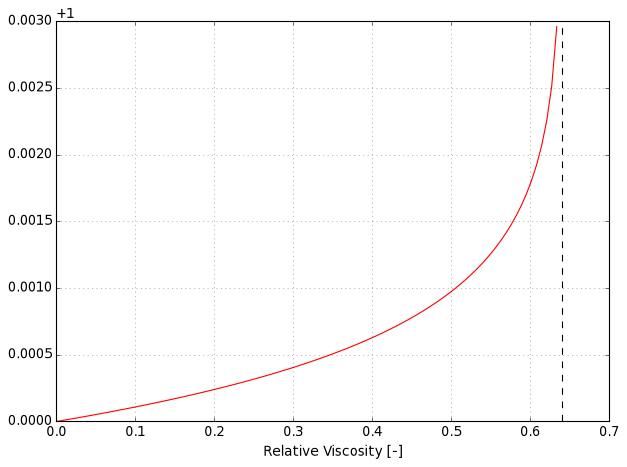

In [51]:
eta0 = 0.001
phim = 0.64

phi = np.linspace(0.0, 0.99*phim, 100)

def residual(eta):
    return krieger_dougherty_model(eta, eta0, phi, phim)

eta_guess = np.ones_like(phi) * eta0
sol = root(residual, eta_guess)
eta_rel = sol.x / eta0

plt.close("all")
plt.style.use("classic")
fig, ax = plt.subplots(facecolor="white")
ax.plot(phi, eta_rel, color="r")
ax.axvline(phim, color="k", linestyle="--")
ax.grid(color="k", linestyle=":", alpha=0.5)
ax.set_xlabel("Particle Volume Fraction [-]")
ax.set_xlabel("Relative Viscosity [-]")
fig.tight_layout()